# Tuần 3 — Thực hành: Giới thiệu học máy và quy trình xây dựng mô hình

**Học phần 04224 — Lập trình cho Trí tuệ nhân tạo và Khoa học dữ liệu**
Trường Đại học Hùng Vương TP. Hồ Chí Minh — Khoa Kỹ thuật Công nghệ

| | |
|---|---|
| **Tuần** | 3 |
| **Chủ đề** | Học máy là gì · quy trình bảy bước · baseline · API scikit-learn · quá khớp và thiếu khớp |
| **Chuẩn đầu ra** | **CLO3** cài đặt và đánh giá mô hình học máy cơ bản · **CLO4** trình bày kết quả và trực quan hóa · **CLO5** tự nghiên cứu, mở rộng sang công cụ mới |
| **Thời lượng** | **3 tiết — khoảng 150 phút**, làm tại phòng máy, có giám sát |
| **Dữ liệu** | `../lab_data/khachhang.csv` — 1500 khách hàng, nhãn `roi_bo` (1 = rời bỏ, 0 = ở lại) |

### Sinh viên nộp gì

Chính notebook này, **đã chạy từ đầu đến cuối không lỗi**, đổi tên thành
`Tuan03_ThucHanh_<MSSV>.ipynb`, nộp trước khi rời phòng máy. Bài nộp phải có:

1. Toàn bộ ô mã đã điền và đã chạy, giữ nguyên kết quả in ra.
2. Bốn phần **trả lời bằng chữ** (Task 1 Bước 1, Task 1 Bước 5, Task 2, Task 3) — viết trực tiếp vào ô Markdown, mỗi phần 3–5 câu.
3. Đồ thị quá khớp của Task 3.
4. Hàm `report()` của Task 4 chạy được.

### Phân bổ thời gian

| Phần | Nội dung | Thời gian |
|---|---|---|
| Task 1 | Quy trình bảy bước từ đầu đến cuối + baseline | ~50 phút |
| Task 2 | Tính đồng nhất của API scikit-learn | ~25 phút |
| Task 3 | Cố ý làm mô hình quá khớp | ~35 phút |
| Task 4 | Hàm `report()` dùng lại cả học kỳ | ~30 phút |
| Mở rộng | Kiểm định chéo (làm nếu còn thời gian) | phần dư |

## Trước khi bắt đầu — ba quy tắc

**1. `random_state = 42` ở mọi nơi.** Mọi chỗ có yếu tố ngẫu nhiên — chia dữ liệu, cây quyết định,
rừng ngẫu nhiên — đều phải nhận `random_state=RANDOM_STATE`.

**Vì sao tính tái lập được chấm điểm:** giảng viên mở notebook của bạn và chạy lại từ đầu.
Nếu con số in ra khác con số bạn ghi trong phần trả lời, bài không chấm được — không phân biệt
được bạn ghi sai hay chỉ là ngẫu nhiên khác. Một kết quả không lặp lại được thì không phải kết quả.
Đây là chuẩn nghề nghiệp, không phải hình thức: mô hình nào cũng phải dựng lại được từ mã nguồn.

**2. Chạy tuần tự từ trên xuống.** Các ô phụ thuộc vào biến của ô trước. Nếu rối, dùng
*Kernel → Restart & Run All*.

**3. Đọc "Kết quả mong đợi" trước khi viết mã.** Mỗi task có một ô nêu rõ con số bạn phải ra.
Nếu lệch, dừng lại sửa — đừng chạy tiếp.

> **Con số quan trọng nhất của buổi hôm nay là 79%.** Bạn sẽ tự tính ra nó ở Task 1.
> Từ đó trở đi, mọi mô hình đều bị so với nó.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn

from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, classification_report)

RANDOM_STATE = 42          # KHÔNG đổi con số này

print("Python      ", sys.version.split()[0])
print("numpy       ", np.__version__)
print("pandas      ", pd.__version__)
print("scikit-learn", sklearn.__version__)

Python       3.13.2
numpy        2.5.3
pandas       3.0.6
scikit-learn 1.9.1


In [2]:
DATA_PATH = Path("../lab_data/khachhang.csv")

if not DATA_PATH.exists():
    if Path("khachhang.csv").exists():
        DATA_PATH = Path("khachhang.csv")
    else:
        raise FileNotFoundError(
            f"Không tìm thấy tệp dữ liệu: {DATA_PATH.resolve()}\n"
            f"Thư mục hiện tại đang là: {Path.cwd()}\n"
            "Notebook này phải nằm trong thư mục lab_exercises/, đặt cạnh thư mục lab_data/.\n"
            "Cấu trúc đúng:  P4AI-DS/lab_data/khachhang.csv  và  P4AI-DS/lab_exercises/<notebook>.ipynb"
        )

kh = pd.read_csv(DATA_PATH)
print("Kích thước:", kh.shape)
print()
print(kh.dtypes)
assert kh.shape == (1500, 8), "Tệp dữ liệu phải có 1500 dòng và 8 cột"
kh.head()

Kích thước: (1500, 8)

ma_kh                   str
thang_gan_nhat      float64
tong_chi_tieu       float64
so_don                int64
so_ticket_ho_tro      int64
kenh_ua_thich           str
tinh_tp                 str
roi_bo                int64
dtype: object


,ma_kh,thang_gan_nhat,tong_chi_tieu,so_don,so_ticket_ho_tro,kenh_ua_thich,tinh_tp,roi_bo
0,KH00001,15.2,2691000.0,3,3,Cửa hàng,Hà Nội,0
1,KH00002,9.5,8262000.0,5,0,Online,Đồng Nai,0
2,KH00003,11.9,10198000.0,6,3,Cửa hàng,Hà Nội,1
3,KH00004,8.1,12981000.0,9,3,Cửa hàng,Hà Nội,0
4,KH00005,13.3,5450000.0,4,3,Online,Khánh Hòa,0


### Từ điển dữ liệu — `khachhang.csv`

| Cột | Ý nghĩa | Kiểu |
|---|---|---|
| `ma_kh` | Mã khách hàng | chuỗi, định danh — **không phải đặc trưng** |
| `thang_gan_nhat` | Số tháng kể từ đơn hàng gần nhất | số thực |
| `tong_chi_tieu` | Tổng chi tiêu trọn đời (VNĐ) | số thực |
| `so_don` | Số đơn đã đặt | số nguyên |
| `so_ticket_ho_tro` | Số phiếu yêu cầu hỗ trợ (0–3) | số nguyên |
| `kenh_ua_thich` | Online / Cửa hàng | phân loại |
| `tinh_tp` | 8 tỉnh/thành | phân loại |
| **`roi_bo`** | **Nhãn: 1 = đã rời bỏ, 0 = còn ở lại** | số nguyên |

Tuần này ta chỉ dùng **bốn cột số**. Hai cột phân loại cần `OneHotEncoder` và `ColumnTransformer` —
đó là nội dung Tuần 4. `ma_kh` là định danh: đưa vào mô hình là sai về nguyên tắc, vì nó không mang
thông tin tổng quát hóa được cho khách hàng mới.

---
# Task 1 — Chạy trọn quy trình bảy bước (~50 phút)

**Mục tiêu.** Đi hết bảy bước xây dựng mô hình trên dữ liệu rời bỏ khách hàng, và học bài học
quan trọng nhất của tuần: **một con số accuracy không kèm baseline thì vô nghĩa.**

Bảy bước, đúng thứ tự — và bạn sẽ làm lại đúng bảy bước này ở mọi tuần còn lại:

| Bước | Tên | Ô bên dưới |
|---|---|---|
| 1 | Xác định bài toán và tiêu chí thành công | 1.1 – 1.3 |
| 2 | Chuẩn bị đặc trưng và nhãn | 1.4 |
| 3 | Chia dữ liệu | 1.5 – 1.6 |
| 4 | Chọn và huấn luyện mô hình | 1.7 |
| 5 | Đánh giá trên dữ liệu chưa thấy | 1.8 – 1.9 |
| 6 | Tinh chỉnh | 1.10 |
| 7 | Trình bày | 1.11 |

> **Quy tắc bắt buộc của Task 1: tính baseline TRƯỚC KHI huấn luyện bất kỳ mô hình nào.**
> Bước 1.3 phải chạy xong và con số phải được ghi lại trước khi bạn gọi `fit()` lần đầu.

### Kết quả mong đợi

- Tỷ lệ rời bỏ toàn bộ dữ liệu: **0.2087** (20,87 %)
- Baseline lớp đa số trên toàn bộ dữ liệu: **0.7913**
- Baseline lớp đa số trên tập kiểm tra: **0.7900** (237 / 300 khách ở lại)
- `X_train` có dạng `(1200, 4)`, `X_test` có dạng `(300, 4)`
- Ba mô hình trên tập kiểm tra:

| Mô hình | accuracy | precision | recall | F1 |
|---|---|---|---|---|
| `DummyClassifier` | 0.7900 | 0.0000 | 0.0000 | 0.0000 |
| `LogisticRegression` | 0.7867 | 0.4783 | 0.1746 | 0.2558 |
| `DecisionTreeClassifier` | 0.7167 | 0.3281 | 0.3333 | 0.3307 |

Nếu bạn thấy đúng ba dòng này thì mọi thứ đã chạy chuẩn — kể cả khi kết quả trông rất tệ.
Kết quả tệ là có chủ ý.

### Bước 1 — Xác định bài toán và tiêu chí thành công

**1.1 — Trả lời bằng chữ.** Điền vào chỗ trống, viết thành câu hoàn chỉnh.

1. **Bài toán này là hồi quy hay phân lớp? Vì sao?**
   *Trả lời: Đây là bài toán **phân lớp (classification)**, cụ thể là phân lớp nhị phân (binary classification). Lý do là vì biến mục tiêu cần dự đoán (`roi_bo`) mang giá trị rời rạc gồm hai trạng thái: 1 (khách hàng rời bỏ) và 0 (khách hàng ở lại), chứ không phải là một đại lượng số liên tục như trong bài toán hồi quy.*

2. **Học có giám sát hay không giám sát? Vì sao?**
   *Trả lời: Đây là bài toán **học có giám sát (supervised learning)**. Lý do là vì tập dữ liệu huấn luyện đã có sẵn nhãn đầu ra thực tế (`roi_bo`), mô hình học mối quan hệ ánh xạ giữa các đặc trưng đầu vào và nhãn đã biết để dự đoán nhãn cho các mẫu mới chưa từng thấy.*

3. **Đặc trưng là gì, nhãn là gì?**
   *Trả lời: Đặc trưng ($X$) là các thuộc tính mô tả hành vi của khách hàng gồm 4 cột số: `thang_gan_nhat` (số tháng kể từ đơn hàng gần nhất), `tong_chi_tieu` (tổng chi tiêu trọn đời tính bằng VNĐ), `so_don` (số đơn hàng đã đặt), và `so_ticket_ho_tro` (số phiếu hỗ trợ kỹ thuật/chăm sóc khách hàng). Nhãn ($y$) là cột `roi_bo`, thể hiện trạng thái khách hàng (1 = đã rời bỏ, 0 = còn ở lại).*

4. **Tiêu chí thành công.** Công ty dùng mô hình này để chọn khách hàng gửi voucher giữ chân.
   Gửi nhầm voucher cho người vốn sẽ ở lại tốn 50 000 đ. Bỏ sót một người sắp rời bỏ mất trung
   bình 1 200 000 đ doanh thu tương lai. **Với chi phí lệch nhau như vậy, độ đo nào quan trọng
   hơn — precision hay recall? Viết một câu bảo vệ lựa chọn của bạn.**
   *Trả lời: **Recall** quan trọng hơn rất nhiều so với Precision. Chi phí của việc bỏ sót một khách hàng sắp rời bỏ (False Negative: mất 1.200.000 đ doanh thu tương lai) lớn gấp 24 lần chi phí gửi nhầm voucher cho người ở lại (False Positive: tốn 50.000 đ), do đó mục tiêu kinh doanh hàng đầu là phải đạt Recall cao nhất có thể để tối đa hóa số khách hàng rời bỏ được phát hiện và giữ chân kịp thời.*

In [3]:
# 1.2 — Nhìn vào nhãn TRƯỚC KHI làm bất cứ điều gì khác
# đếm số khách rời bỏ và số khách ở lại
print(kh["roi_bo"].value_counts())

# tính tỷ lệ rời bỏ (trung bình của cột nhãn nhị phân chính là tỷ lệ lớp 1)
ty_le_roi_bo = kh["roi_bo"].mean()
print(f"Tỷ lệ rời bỏ: {ty_le_roi_bo:.4f}")

roi_bo
0    1187
1     313
Name: count, dtype: int64
Tỷ lệ rời bỏ: 0.2087


In [4]:
# 1.3 — BASELINE, TRƯỚC KHI CÓ BẤT KỲ MÔ HÌNH NÀO
# Mô hình ngu ngốc nhất có thể: đoán "không ai rời bỏ" cho tất cả 1500 khách.
# Nó đúng ở mọi khách hàng thuộc lớp đa số.
#
# tính accuracy của quy tắc "đoán lớp đa số cho mọi người"
baseline_toan_bo = (kh["roi_bo"] == 0).mean()

print(f"Baseline lớp đa số: {baseline_toan_bo:.4f}  ({baseline_toan_bo * 100:.2f} %)")
print()
print("GHI LẠI CON SỐ NÀY. Mọi mô hình hôm nay đều bị so với nó.")

assert abs(baseline_toan_bo - 0.7913) < 0.001, (
    "Baseline phải xấp xỉ 0.7913 — kiểm tra lại: baseline là tỷ lệ của lớp ĐA SỐ")

Baseline lớp đa số: 0.7913  (79.13 %)

GHI LẠI CON SỐ NÀY. Mọi mô hình hôm nay đều bị so với nó.


In [5]:
# BƯỚC 2 — Chuẩn bị đặc trưng và nhãn
# Tuần này chỉ dùng bốn cột số. Cột phân loại để Tuần 4; ma_kh là định danh, loại bỏ.

DAC_TRUNG = ["thang_gan_nhat", "tong_chi_tieu", "so_don", "so_ticket_ho_tro"]

# X là DataFrame chứa các cột đặc trưng, y là Series chứa nhãn
X = kh[DAC_TRUNG]
y = kh["roi_bo"]

print("X:", X.shape, "| y:", y.shape)
assert X.shape == (1500, 4), "X phải là (1500, 4)"
assert y.shape == (1500,), "y phải là (1500,)"
assert "roi_bo" not in X.columns, "NHÃN KHÔNG ĐƯỢC NẰM TRONG X — đó là rò rỉ dữ liệu"
assert "ma_kh" not in X.columns, "Bỏ cột định danh ra khỏi X" 

X: (1500, 4) | y: (1500,)


In [6]:
# BƯỚC 3 — Chia dữ liệu
# stratify=y giữ nguyên tỷ lệ 79/21 ở cả hai phía. Không có nó, với lớp thiểu số nhỏ,
# tập kiểm tra có thể lệch tỷ lệ chỉ vì may rủi và mọi con số sau đó đều sai lệch.

# chia 80 / 20, phân tầng theo y, cố định random_state
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)

print("X_train:", X_train.shape, "| X_test:", X_test.shape)
print(f"Tỷ lệ rời bỏ  train = {y_train.mean():.4f} | test = {y_test.mean():.4f}")

assert X_train.shape == (1200, 4) and X_test.shape == (300, 4)
assert abs(y_train.mean() - y_test.mean()) < 0.01, "stratify=y chưa được dùng?" 

X_train: (1200, 4) | X_test: (300, 4)
Tỷ lệ rời bỏ  train = 0.2083 | test = 0.2100


In [7]:
# 1.6 — Baseline tính lại trên đúng tập kiểm tra sẽ dùng để chấm mô hình
# tỷ lệ khách ở lại trong y_test
baseline_test = (y_test == 0).mean()

print(f"Baseline trên tập kiểm tra: {baseline_test:.4f}")
print(f"  = {(y_test == 0).sum()} khách ở lại / {len(y_test)} khách trong tập kiểm tra")

assert abs(baseline_test - 0.79) < 1e-9, "Baseline tập kiểm tra phải đúng bằng 0.79" 

Baseline trên tập kiểm tra: 0.7900
  = 237 khách ở lại / 300 khách trong tập kiểm tra


In [8]:
# BƯỚC 4 — Chọn và huấn luyện mô hình
# Ba mô hình, cùng một giao ước: khởi tạo -> .fit(X_train, y_train)

# DummyClassifier đoán lớp đa số — chính là baseline, nhưng dưới dạng một estimator
dummy = DummyClassifier(strategy="most_frequent")
dummy.fit(X_train, y_train)

# LogisticRegression, max_iter=1000, random_state=RANDOM_STATE
logreg = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
logreg.fit(X_train, y_train)

# DecisionTreeClassifier để nguyên mặc định (KHÔNG giới hạn độ sâu), random_state=RANDOM_STATE
cay = DecisionTreeClassifier(random_state=RANDOM_STATE)
cay.fit(X_train, y_train)

print("Đã huấn luyện xong 3 mô hình.")

Đã huấn luyện xong 3 mô hình.


In [9]:
# BƯỚC 5 — Đánh giá trên dữ liệu chưa thấy
# Accuracy KHÔNG đủ. Với mỗi mô hình, in: accuracy, chênh lệch so với baseline,
# ma trận nhầm lẫn, và precision/recall/F1.

for ten, mo_hinh in [("DummyClassifier", dummy),
                     ("LogisticRegression", logreg),
                     ("DecisionTreeClassifier", cay)]:
    # dự đoán trên tập kiểm tra
    y_pred = mo_hinh.predict(X_test)
    # tính accuracy
    acc = accuracy_score(y_test, y_pred)

    print("=" * 62)
    print(f"{ten}")
    print(f"  accuracy = {acc:.4f} | baseline = {baseline_test:.4f} "
          f"| chênh lệch = {acc - baseline_test:+.4f}")
    print()
    # in ma trận nhầm lẫn
    print("  Ma trận nhầm lẫn  [[TN FP] [FN TP]]:")
    print(confusion_matrix(y_test, y_pred))
    print()
    # in classification_report (dùng zero_division=0)
    print(classification_report(y_test, y_pred, zero_division=0))

DummyClassifier
  accuracy = 0.7900 | baseline = 0.7900 | chênh lệch = +0.0000

  Ma trận nhầm lẫn  [[TN FP] [FN TP]]:
[[237   0]
 [ 63   0]]

              precision    recall  f1-score   support

           0       0.79      1.00      0.88       237
           1       0.00      0.00      0.00        63

    accuracy                           0.79       300
   macro avg       0.40      0.50      0.44       300
weighted avg       0.62      0.79      0.70       300

LogisticRegression
  accuracy = 0.7867 | baseline = 0.7900 | chênh lệch = -0.0033

  Ma trận nhầm lẫn  [[TN FP] [FN TP]]:
[[225  12]
 [ 52  11]]

              precision    recall  f1-score   support

           0       0.81      0.95      0.88       237
           1       0.48      0.17      0.26        63

    accuracy                           0.79       300
   macro avg       0.65      0.56      0.57       300
weighted avg       0.74      0.79      0.75       300

DecisionTreeClassifier
  accuracy = 0.7167 | baseline = 0

In [10]:
# 1.9 — Câu hỏi then chốt: mỗi mô hình bắt được bao nhiêu khách sắp rời bỏ?
# Trong 300 khách của tập kiểm tra có đúng 63 người thật sự rời bỏ.

print(f"Số khách thật sự rời bỏ trong tập kiểm tra: {int(y_test.sum())}")
print()
for ten, mo_hinh in [("DummyClassifier", dummy),
                     ("LogisticRegression", logreg),
                     ("DecisionTreeClassifier", cay)]:
    y_pred = mo_hinh.predict(X_test)
    tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
    print(f"{ten:24s} bắt được {tp:2d}/63 | bỏ sót {fn:2d} | báo động nhầm {fp:2d}")

Số khách thật sự rời bỏ trong tập kiểm tra: 63

DummyClassifier          bắt được  0/63 | bỏ sót 63 | báo động nhầm  0
LogisticRegression       bắt được 11/63 | bỏ sót 52 | báo động nhầm 12
DecisionTreeClassifier   bắt được 21/63 | bỏ sót 42 | báo động nhầm 43


**1.9b — Trả lời bằng chữ (bắt buộc).**

`DummyClassifier` đạt **79,00 %** accuracy — cao hơn `DecisionTreeClassifier` (**71,67 %**) và
gần bằng `LogisticRegression` (**78,67 %**). Nhưng nó bắt được **0 trong 63** khách sắp rời bỏ.

**Viết 3–5 câu giải thích vì sao chỉ nhìn accuracy là sai lầm ở bài toán này.** Bài viết phải nêu
được: (a) dữ liệu mất cân bằng nghĩa là gì và ở đây mất cân bằng bao nhiêu; (b) một mô hình không
bao giờ dự đoán lớp 1 vẫn có thể có accuracy cao như thế nào; (c) độ đo nào phản ánh đúng giá trị
kinh doanh, dựa trên chi phí bạn đã phân tích ở Bước 1.1.

*Trả lời:*
1. Dữ liệu bài toán có sự mất cân bằng đáng kể giữa hai lớp: nhóm khách hàng ở lại chiếm tới 79,00% (237/300 khách ở tập kiểm tra), trong khi nhóm khách hàng rời bỏ chỉ chiếm tỷ lệ thiểu số là 21,00% (63/300 khách).
2. Khi dữ liệu mất cân bằng, một mô hình tầm thường chỉ cần luôn đoán nhãn 0 (không ai rời bỏ) như `DummyClassifier` thì tự động đạt độ chính xác Accuracy lên tới 79,00% dù hoàn toàn vô dụng vì không phát hiện được bất kỳ ai rời bỏ (bắt được 0/63 khách, Recall = 0%).
3. Trong bài toán kinh doanh này, việc bỏ sót một khách hàng rời bỏ gây thiệt hại tới 1.200.000 đ doanh thu, lớn gấp 24 lần chi phí gửi nhầm voucher (50.000 đ), do đó mục tiêu tối thượng là phải hạn chế tối đa việc bỏ sót khách hàng.
4. Vì vậy, chỉ nhìn vào Accuracy sẽ dẫn đến ảo tưởng và đánh giá sai hoàn toàn hiệu quả; thay vào đó, các độ đo như **Recall** (để đo lường tỷ lệ phát hiện khách rời bỏ) và **F1-score** mới phản ánh đúng giá trị kinh doanh thực tế mà mô hình mang lại.

In [11]:
# BƯỚC 6 — Tinh chỉnh
# Tham số dễ thấy nhất của cây quyết định là max_depth. Thử vài giá trị.
# (Task 3 sẽ quét đầy đủ và giải thích vì sao đường cong có hình dạng như vậy.)

print(f"{'max_depth':>10} | {'accuracy':>8} | {'F1':>6} | so với baseline")
print("-" * 52)
for do_sau in [2, 3, 4, 5, 8, None]:
    # huấn luyện cây với max_depth=do_sau, nhớ random_state
    t = DecisionTreeClassifier(max_depth=do_sau, random_state=RANDOM_STATE)
    t.fit(X_train, y_train)
    y_pred = t.predict(X_test)
    acc = accuracy_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred, zero_division=0)
    print(f"{str(do_sau):>10} | {acc:8.4f} | {f1:6.4f} | {acc - baseline_test:+.4f}")

 max_depth | accuracy |     F1 | so với baseline
----------------------------------------------------
         2 |   0.7900 | 0.0000 | +0.0000
         3 |   0.7933 | 0.0606 | +0.0033
         4 |   0.8000 | 0.2683 | +0.0100
         5 |   0.7967 | 0.3441 | +0.0067
         8 |   0.7700 | 0.2247 | -0.0200
      None |   0.7167 | 0.3307 | -0.0733


### Bước 7 — Trình bày

**1.11 — Tóm tắt Task 1.** Điền vào bảng và viết kết luận một câu.

| Mô hình | accuracy | Hơn/kém baseline 0.7900 | Bắt được bao nhiêu / 63 |
|---|---|---|---|
| `DummyClassifier` | 0.7900 | +0.0000 | 0 / 63 |
| `LogisticRegression` | 0.7867 | -0.0033 | 11 / 63 |
| `DecisionTreeClassifier` | 0.7167 | -0.0733 | 21 / 63 |

**Kết luận (một câu): nếu hôm nay phải đưa một mô hình vào chạy thật, bạn chọn mô hình nào và vì sao?**

*Trả lời: Nếu hôm nay phải đưa một mô hình vào chạy thực tế, tôi chọn **`DecisionTreeClassifier`** vì mô hình này có khả năng phát hiện được nhiều khách hàng sắp rời bỏ nhất (bắt được 21/63 khách hàng, đạt Recall 33.33% và F1-score 0.3307 cao nhất trong 3 mô hình), qua đó giúp doanh nghiệp kịp thời gửi voucher giữ chân và bảo vệ được nguồn doanh thu lớn nhất.*

---
# Task 2 — Giao ước estimator đồng nhất (~25 phút)

**Mục tiêu.** Chứng minh bằng tay rằng mọi mô hình trong scikit-learn đều tuân theo cùng một giao
ước `fit` / `predict` / `score`, nên đổi mô hình chỉ tốn **một dòng**.

**Các bước con**

1. **2.1** — Dựng một `dict` gồm bốn mô hình: `DummyClassifier`, `LogisticRegression`,
   `DecisionTreeClassifier`, `RandomForestClassifier`.
2. **2.2** — Viết **một** vòng lặp huấn luyện và chấm cả bốn. **Thân vòng lặp không được có bất kỳ
   câu `if` nào theo tên mô hình.** Nếu bạn phải viết `if ten == ...` thì bạn đã hiểu sai bài này.
3. **2.3** — Gom kết quả vào một `DataFrame` gồm `mo_hinh`, `accuracy`, `precision`, `recall`, `f1`,
   sắp xếp **giảm dần theo F1**.
4. **2.4** — Trả lời bằng chữ.

**Về `Pipeline` và `StandardScaler`.** `LogisticRegression` tìm nghiệm bằng tối ưu số học, nên nó
nhạy với thang đo của đặc trưng: `tong_chi_tieu` cỡ hàng triệu còn `so_ticket_ho_tro` chỉ từ 0 đến 3,
chênh nhau hơn sáu bậc độ lớn. Cây quyết định và rừng ngẫu nhiên thì không quan tâm — chúng chỉ so
sánh ngưỡng trên từng cột. Để so sánh **công bằng**, ta bọc `LogisticRegression` trong một
`Pipeline` có `StandardScaler` đứng trước. `Pipeline` bản thân nó cũng là một estimator: nó có
`fit` và `predict`, nên thân vòng lặp không cần biết bên trong là gì — đó chính là điều cần chứng minh.

### Kết quả mong đợi

Bảng sắp theo F1 giảm dần, đúng thứ tự này:

| # | mo_hinh | accuracy | precision | recall | f1 |
|---|---|---|---|---|---|
| 0 | `DecisionTreeClassifier` | 0.7167 | 0.3281 | 0.3333 | **0.3307** |
| 1 | `RandomForestClassifier` | 0.7767 | 0.4444 | 0.2540 | 0.3232 |
| 2 | `LogisticRegression` | 0.7933 | 0.5294 | 0.1429 | 0.2250 |
| 3 | `DummyClassifier` | 0.7900 | 0.0000 | 0.0000 | 0.0000 |

Nhìn kỹ cột `accuracy`: nó **giảm dần đều theo chiều ngược lại**. Thứ tự xếp hạng theo accuracy
đảo ngược hoàn toàn thứ tự xếp hạng theo F1. Đây không phải trùng hợp, và bạn sẽ giải thích nó ở 2.4.

In [12]:
# 2.1 — Bốn ứng viên. Chỉ khác nhau ở VẾ PHẢI của dấu bằng.

ung_vien = {
    "DummyClassifier": DummyClassifier(strategy="most_frequent"),

    # LogisticRegression bọc trong Pipeline có StandardScaler
    #   Pipeline([("scaler", ...), ("model", ...)])
    "LogisticRegression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))
    ]),

    # DecisionTreeClassifier mặc định, random_state=RANDOM_STATE
    "DecisionTreeClassifier": DecisionTreeClassifier(random_state=RANDOM_STATE),

    # RandomForestClassifier, n_estimators=100, random_state=RANDOM_STATE
    "RandomForestClassifier": RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE),
}

for ten, mo_hinh in ung_vien.items():
    print(f"{ten:24s} -> {type(mo_hinh).__name__}")

DummyClassifier          -> DummyClassifier
LogisticRegression       -> Pipeline
DecisionTreeClassifier   -> DecisionTreeClassifier
RandomForestClassifier   -> RandomForestClassifier


In [13]:
# 2.2 + 2.3 — MỘT vòng lặp cho cả bốn mô hình.
# Thân vòng lặp phải giống hệt nhau với mọi mô hình. Không có if theo tên mô hình.

ket_qua = []
for ten, mo_hinh in ung_vien.items():
    # ba dòng sau là toàn bộ "giao ước estimator" — viết chúng ra
    mo_hinh.fit(X_train, y_train)          # huấn luyện trên tập huấn luyện
    y_pred = mo_hinh.predict(X_test)              # dự đoán trên tập kiểm tra

    ket_qua.append({
        "mo_hinh":   ten,
        "accuracy":  accuracy_score(y_test, y_pred),
        # ba độ đo còn lại, nhớ zero_division=0
        "precision": precision_score(y_test, y_pred, zero_division=0),
        "recall":    recall_score(y_test, y_pred, zero_division=0),
        "f1":        f1_score(y_test, y_pred, zero_division=0),
    })

# tạo DataFrame và sắp xếp giảm dần theo cột f1
bang = pd.DataFrame(ket_qua).sort_values("f1", ascending=False)
bang = bang.reset_index(drop=True)
bang["hon_baseline"] = bang["accuracy"] - baseline_test

print(bang.round(4).to_string())

                  mo_hinh  accuracy  precision  recall      f1  hon_baseline
0  DecisionTreeClassifier    0.7167     0.3281  0.3333  0.3307       -0.0733
1  RandomForestClassifier    0.7767     0.4444  0.2540  0.3232       -0.0133
2      LogisticRegression    0.7933     0.5294  0.1429  0.2250        0.0033
3         DummyClassifier    0.7900     0.0000  0.0000  0.0000        0.0000


In [14]:
# 2.3b — Tự kiểm tra
assert len(bang) == 4, "Phải có đúng 4 mô hình"
assert list(bang.columns)[:5] == ["mo_hinh", "accuracy", "precision", "recall", "f1"]
assert bang["f1"].is_monotonic_decreasing, "Bảng phải được sắp giảm dần theo F1"
assert bang.loc[0, "mo_hinh"] == "DecisionTreeClassifier", \
    "Với seed 42, mô hình có F1 cao nhất là DecisionTreeClassifier"
assert bang.loc[3, "mo_hinh"] == "DummyClassifier", "DummyClassifier phải đứng cuối theo F1"
assert bang.loc[3, "f1"] == 0.0, "DummyClassifier không bao giờ dự đoán lớp 1 nên F1 = 0"

# Xếp hạng theo accuracy — so sánh với xếp hạng theo F1 ở trên
print("Xếp hạng theo ACCURACY giảm dần:")
print(bang.sort_values("accuracy", ascending=False)[["mo_hinh", "accuracy", "f1"]]
        .round(4).to_string(index=False))
print()
print("Tất cả đã chạy đúng.")

Xếp hạng theo ACCURACY giảm dần:
               mo_hinh  accuracy     f1
    LogisticRegression    0.7933 0.2250
       DummyClassifier    0.7900 0.0000
RandomForestClassifier    0.7767 0.3232
DecisionTreeClassifier    0.7167 0.3307

Tất cả đã chạy đúng.


**2.4 — Trả lời bằng chữ (bắt buộc).** 3–5 câu.

1. Trong vòng lặp ở ô 2.2, có bao nhiêu dòng mã phải thay đổi khi chuyển từ mô hình này sang mô
   hình khác? Điều đó nói lên gì về thiết kế của scikit-learn?
2. Vì sao `Pipeline` + `StandardScaler` là **bắt buộc** để so sánh công bằng, chứ không phải tùy chọn?
3. Xếp hạng theo accuracy đảo ngược xếp hạng theo F1. **Nếu công ty triển khai mô hình đứng đầu bảng
   accuracy, chuyện gì xảy ra trong thực tế?**

*Trả lời:*
1. Trong vòng lặp ở ô 2.2, **không có bất kỳ dòng mã nào** phải thay đổi khi chuyển đổi qua lại giữa các mô hình (0 dòng thay đổi). Điều này thể hiện triết lý thiết kế hướng đối tượng xuất sắc và tính nhất quán cao của scikit-learn thông qua "Giao ước Estimator" (Estimator API) thống nhất với các phương thức chuẩn `.fit()` và `.predict()`, giúp việc thử nghiệm, so sánh và thay thế mô hình diễn ra cực kỳ linh hoạt mà không làm thay đổi luồng xử lý mã nguồn.
2. `Pipeline` + `StandardScaler` là bắt buộc vì mô hình Logistic Regression sử dụng thuật toán tối ưu hóa số học dựa trên gradient, rất nhạy cảm với chênh lệch thang đo độ lớn giữa các đặc trưng (`tong_chi_tieu` lên tới hàng chục triệu trong khi `so_ticket_ho_tro` chỉ từ 0 đến 3). Trong khi đó các mô hình cây quyết định hay rừng ngẫu nhiên bất biến với thang đo đặc trưng; vì vậy việc chuẩn hóa là điều kiện tiên quyết để đảm bảo tính công bằng và giúp Logistic Regression hội tụ về nghiệm tối ưu.
3. Nếu công ty triển khai mô hình đứng đầu bảng Accuracy (`LogisticRegression` đạt 0.7933 hoặc `DummyClassifier` đạt 0.7900), trên thực tế hệ thống sẽ hầu như đoán toàn bộ khách hàng là ở lại và bỏ sót đại đa số khách hàng sắp rời bỏ (Recall chỉ đạt 14.29% ở Logistic Regression và 0% ở Dummy). Kết quả là doanh nghiệp đánh mất một lượng lớn khách hàng cùng khoản doanh thu khổng lồ mà không hề hay biết do bị đánh lừa bởi con số Accuracy cao nhưng vô nghĩa.

---
# Task 3 — Cố ý tạo quá khớp (~35 phút)

**Mục tiêu.** Nhìn tận mắt hiện tượng **quá khớp** (overfitting) và **thiếu khớp** (underfitting)
trên một đồ thị, bằng cách tăng dần dung lượng mô hình và theo dõi hai đường cong tách nhau ra.

**Các bước con**

1. **3.1** — Huấn luyện `DecisionTreeClassifier` với `max_depth` chạy từ **1 đến 25**. Ở mỗi độ sâu,
   ghi lại accuracy trên **tập huấn luyện** và accuracy trên **tập kiểm tra**.
2. **3.2** — Vẽ **cả hai đường trên cùng một hình**, kèm đường ngang baseline 0.79.
3. **3.3** — Xác định độ sâu cho accuracy tập kiểm tra cao nhất, và độ sâu mà hai đường bắt đầu
   tách nhau rõ rệt.
4. **3.4** — Xác nhận cây không giới hạn độ sâu đạt accuracy huấn luyện bằng **1.00**.
5. **3.5** — Trả lời bằng chữ: vùng nào thiếu khớp, vùng nào quá khớp.

### Kết quả mong đợi

| Độ sâu | accuracy train | accuracy test | khoảng cách |
|---|---|---|---|
| 1 | 0.7917 | 0.7900 | 0.0017 |
| 2 | 0.7917 | 0.7900 | 0.0017 |
| 3 | 0.7942 | 0.7933 | 0.0008 |
| **4** | 0.8117 | **0.8000** ← cao nhất | 0.0117 |
| 5 | 0.8292 | 0.7967 | 0.0325 |
| 6 | 0.8442 | 0.7900 | 0.0542 ← bắt đầu phân kỳ |
| 10 | 0.9267 | 0.7567 | 0.1700 |
| 15 | 0.9958 | 0.7167 | 0.2792 |
| 20–25 | **1.0000** | 0.7167 | 0.2833 |

- Độ sâu tốt nhất theo accuracy tập kiểm tra: **4** (duy nhất, không hòa)
- Độ sâu đầu tiên khoảng cách train − test vượt 5 điểm phần trăm: **6**
- Cây không giới hạn: train = **1.0000**, test = **0.7167**, độ sâu thực tế **20**, **275 lá**
- Đồ thị: đường train đi lên mãi tới 1,0; đường test lên tới đỉnh ở độ sâu 4 rồi rơi xuống **dưới**
  đường baseline và ở lại đó.

In [15]:
# 3.1 — Quét độ sâu từ 1 đến 25
do_sau_list = list(range(1, 26))
acc_train, acc_test = [], []

for d in do_sau_list:
    # huấn luyện cây với max_depth=d và random_state=RANDOM_STATE
    t = DecisionTreeClassifier(max_depth=d, random_state=RANDOM_STATE)
    t.fit(X_train, y_train)
    # .score() trả về accuracy — dùng nó cho cả hai tập
    acc_train.append(t.score(X_train, y_train))
    acc_test.append(t.score(X_test, y_test))

quet = pd.DataFrame({"max_depth": do_sau_list, "train": acc_train, "test": acc_test})
quet["khoang_cach"] = quet["train"] - quet["test"]
print(quet.round(4).to_string(index=False))

 max_depth  train   test  khoang_cach
         1 0.7917 0.7900       0.0017
         2 0.7917 0.7900       0.0017
         3 0.7942 0.7933       0.0008
         4 0.8117 0.8000       0.0117
         5 0.8292 0.7967       0.0325
         6 0.8442 0.7900       0.0542
         7 0.8633 0.7867       0.0767
         8 0.8867 0.7700       0.1167
         9 0.9050 0.7500       0.1550
        10 0.9267 0.7567       0.1700
        11 0.9442 0.7433       0.2008
        12 0.9633 0.7433       0.2200
        13 0.9775 0.7233       0.2542
        14 0.9883 0.7233       0.2650
        15 0.9958 0.7167       0.2792
        16 0.9983 0.7200       0.2783
        17 0.9967 0.7233       0.2733
        18 0.9975 0.7067       0.2908
        19 0.9992 0.7233       0.2758
        20 1.0000 0.7167       0.2833
        21 1.0000 0.7167       0.2833
        22 1.0000 0.7167       0.2833
        23 1.0000 0.7167       0.2833
        24 1.0000 0.7167       0.2833
        25 1.0000 0.7167       0.2833


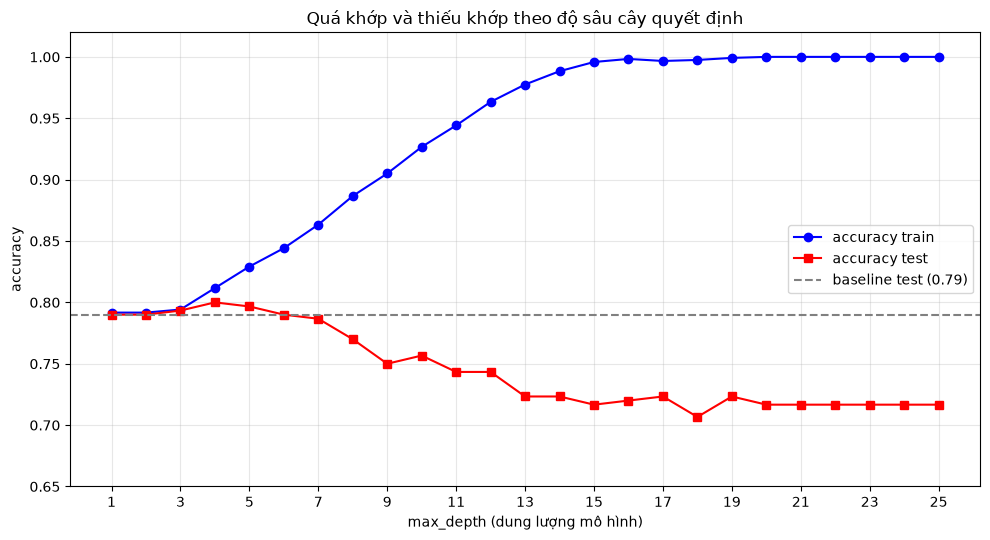

In [16]:
# 3.2 — Hai đường cong trên cùng một hình
plt.figure(figsize=(10, 5.5))

# vẽ đường accuracy tập huấn luyện
plt.plot(do_sau_list, acc_train, "b-o", label="accuracy train")
# vẽ đường accuracy tập kiểm tra
plt.plot(do_sau_list, acc_test, "r-s", label="accuracy test")
# vẽ đường ngang baseline (dùng plt.axhline)
plt.axhline(y=baseline_test, color="gray", linestyle="--", label=f"baseline test ({baseline_test:.2f})")

plt.xlabel("max_depth (dung lượng mô hình)")
plt.ylabel("accuracy")
plt.title("Quá khớp và thiếu khớp theo độ sâu cây quyết định")
plt.xticks(do_sau_list[::2])
plt.ylim(0.65, 1.02)
plt.legend(loc="center right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [17]:
# 3.3 — Định vị đỉnh và điểm phân kỳ
# độ sâu có accuracy tập kiểm tra cao nhất (gợi ý: .idxmax())
do_sau_tot_nhat = quet.loc[quet["test"].idxmax(), "max_depth"]
print(f"Accuracy test cao nhất: {quet['test'].max():.4f} tại max_depth = {do_sau_tot_nhat}")

# độ sâu ĐẦU TIÊN có khoảng cách train - test vượt 0.05
do_sau_phan_ky = quet.loc[quet["khoang_cach"] > 0.05, "max_depth"].iloc[0]
print(f"Hai đường bắt đầu tách rõ (khoảng cách > 5 điểm %) từ max_depth = {do_sau_phan_ky}")

# độ sâu đầu tiên mà accuracy test tụt xuống DƯỚI baseline
do_sau_thua_baseline = quet.loc[quet["test"] < baseline_test, "max_depth"].iloc[0]
print(f"Từ max_depth = {do_sau_thua_baseline} trở đi, mô hình TỆ HƠN cả việc đoán lớp đa số")

assert do_sau_tot_nhat == 4, "Với seed 42, đỉnh nằm ở max_depth = 4"
assert do_sau_phan_ky == 6, "Với seed 42, khoảng cách vượt 5 điểm % lần đầu ở max_depth = 6" 

Accuracy test cao nhất: 0.8000 tại max_depth = 4
Hai đường bắt đầu tách rõ (khoảng cách > 5 điểm %) từ max_depth = 6
Từ max_depth = 7 trở đi, mô hình TỆ HƠN cả việc đoán lớp đa số


In [18]:
# 3.4 — Cây không giới hạn độ sâu: học thuộc lòng tập huấn luyện
# DecisionTreeClassifier KHÔNG đặt max_depth, chỉ đặt random_state
cay_vo_han = DecisionTreeClassifier(random_state=RANDOM_STATE)
cay_vo_han.fit(X_train, y_train)

acc_tr = cay_vo_han.score(X_train, y_train)
acc_te = cay_vo_han.score(X_test, y_test)

print(f"accuracy tập huấn luyện = {acc_tr:.4f}")
print(f"accuracy tập kiểm tra   = {acc_te:.4f}")
print(f"khoảng cách             = {acc_tr - acc_te:.4f}")
print()
print(f"Độ sâu thực tế cây tự dừng: {cay_vo_han.get_depth()}")
print(f"Số lá: {int(cay_vo_han.get_n_leaves())} lá cho {len(X_train)} mẫu huấn luyện "
      f"({len(X_train) / cay_vo_han.get_n_leaves():.1f} mẫu / lá)")

assert acc_tr == 1.0, "Cây không giới hạn phải đạt accuracy huấn luyện đúng bằng 1.0"
assert acc_te < baseline_test, "và phải TỆ HƠN baseline trên tập kiểm tra" 

accuracy tập huấn luyện = 1.0000
accuracy tập kiểm tra   = 0.7167
khoảng cách             = 0.2833

Độ sâu thực tế cây tự dừng: 20
Số lá: 275 lá cho 1200 mẫu huấn luyện (4.4 mẫu / lá)


**3.5 — Trả lời bằng chữ (bắt buộc).** 3–5 câu, bám vào con số bạn vừa in ra.

1. **Vùng nào của đồ thị là thiếu khớp?** Nêu khoảng `max_depth`, và giải thích vì sao ở đó accuracy
   trên tập huấn luyện cũng thấp chứ không riêng tập kiểm tra.
2. **Vùng nào là quá khớp?** Nêu khoảng `max_depth`, và mô tả điều gì xảy ra với *khoảng cách* giữa
   hai đường.
3. Cây độ sâu 20 đúng **100 %** trên tập huấn luyện. **Vì sao con số đó vô dụng** với người mua mô hình?
4. Nếu chỉ được nhìn đường **train**, bạn có phát hiện được quá khớp không? Điều đó giải thích vì sao
   quy trình bảy bước bắt buộc phải có bước chia dữ liệu.

*Trả lời:*
1. **Vùng thiếu khớp (underfitting)** là khoảng `max_depth` từ 1 đến 3. Tại khoảng này, mô hình có cấu trúc quá đơn giản (cây quá nông) nên không đủ dung lượng để học được các quy luật tiềm ẩn trong dữ liệu, dẫn đến độ chính xác trên tập huấn luyện cũng rất thấp (chỉ từ 0.7917 đến 0.7942), xấp xỉ mức baseline của tập huấn luyện.
2. **Vùng quá khớp (overfitting)** bắt đầu từ `max_depth >= 6` và trở nên đặc biệt nghiêm trọng từ `max_depth >= 10`. Trong vùng này, khoảng cách giữa đường train và đường test ngày càng nới rộng nhanh chóng (vượt 5 điểm % tại độ sâu 6 và lên tới hơn 28 điểm % ở độ sâu 20); đường train liên tục tăng lên tiệm cận 1.0000 trong khi đường test lại đảo chiều giảm sâu xuống dưới mức baseline (chỉ còn 0.7167).
3. Con số độ chính xác 100% trên tập huấn luyện của cây độ sâu 20 là **hoàn toàn vô dụng** đối với người mua mô hình, bởi vì mô hình chỉ đơn thuần là "học vẹt" và ghi nhớ từng mẫu dữ liệu trong quá khứ (kể cả nhiễu ngẫu nhiên), mất đi khả năng tổng quát hóa trên các khách hàng mới mà doanh nghiệp sẽ phục vụ trong tương lai.
4. Nếu chỉ nhìn đường **train**, ta hoàn toàn không thể phát hiện hiện tượng quá khớp vì độ chính xác tập huấn luyện luôn tăng đơn điệu theo độ sâu mô hình; điều này chứng minh việc phân chia dữ liệu (train/test split) trong quy trình 7 bước là bước bắt buộc nhằm cung cấp thước đo khách quan đánh giá năng lực tổng quát hóa thực sự của mô hình trên dữ liệu chưa từng thấy.

---
# Task 4 — Hàm `report()` dùng lại cả học kỳ (~30 phút)

**Nói thẳng: hàm này bạn sẽ dùng lại ở mọi tuần từ giờ đến hết học phần** — Tuần 5 (hồi quy
logistic), Tuần 6 (cây, rừng, SVM), Tuần 9 (phân loại ảnh/văn bản), và trong bài **kiểm tra giữa kỳ
thực hành**. Mỗi lần đánh giá một mô hình mà phải gõ lại năm lời gọi độ đo là một lần có cơ hội gõ
sai. Viết một lần cho tử tế, rồi copy sang notebook tuần sau.

**Yêu cầu.** Viết `report(model, X_test, y_test, name="")` sao cho nó:

1. **In** một bảng độ đo gọn gàng: accuracy, precision, recall, F1.
2. **In** ma trận nhầm lẫn kèm nhãn cho bốn ô (TN, FP, FN, TP), không bắt người đọc tự nhớ vị trí.
3. **In** so sánh với baseline lớp đa số — tự tính từ `y_test`, **không** nhận từ ngoài vào, để hàm
   dùng được với bất kỳ tập kiểm tra nào ở các tuần sau.
4. **Trả về** một `dict` chứa các khóa: `name`, `accuracy`, `precision`, `recall`, `f1`,
   `baseline`, `vs_baseline`, `confusion_matrix`.

Vì sao phải **trả về** dict chứ không chỉ in: in ra thì mắt người đọc được, còn muốn gom kết quả
mười mô hình vào một `DataFrame` thì phải có giá trị trả về. Một hàm vừa in vừa trả về dùng được cả
hai cách.

### Kết quả mong đợi

Gọi `report()` trên bốn mô hình của Task 2, các con số phải **trùng khớp từng chữ số** với bảng ở
Task 2. Nếu lệch, nhiều khả năng bạn đã `fit` lại mô hình ở đâu đó mà quên `random_state`.

Ô tự kiểm tra **4.3 cố ý dùng `logreg` của Task 1** — bản `LogisticRegression` *không* có
`StandardScaler` — nên nó in ra 0.7867 / F1 0.2558, khác với dòng `LogisticRegression` (pipeline)
0.7933 / F1 0.2250 ở ô 4.2. Hai con số này khác nhau là **đúng**, và đó cũng là bằng chứng
`report()` chạy được với cả estimator trần lẫn `Pipeline`. Ô 4.3 phải chạy qua không lỗi.

In [19]:
# 4.1 — Viết hàm. Đây là đoạn mã bạn sẽ mang theo suốt học phần.

def report(model, X_test, y_test, name=""):
    '''In bảng độ đo, ma trận nhầm lẫn và so sánh baseline; trả về dict kết quả.

    Tham số
    -------
    model   : estimator đã được fit (bất kỳ mô hình scikit-learn nào, kể cả Pipeline)
    X_test  : đặc trưng của tập kiểm tra
    y_test  : nhãn thật của tập kiểm tra
    name    : tên hiển thị; để trống thì lấy tên lớp của model
    '''
    # dự đoán
    y_pred = model.predict(X_test)

    # baseline lớp đa số tính TỪ y_test (tỷ lệ của lớp xuất hiện nhiều nhất)
    baseline = (y_test == y_test.value_counts().idxmax()).mean()

    kq = {
        "name":      name or type(model).__name__,
        # bốn độ đo, nhớ zero_division=0
        "accuracy":  accuracy_score(y_test, y_pred),
        "precision": precision_score(y_test, y_pred, zero_division=0),
        "recall":    recall_score(y_test, y_pred, zero_division=0),
        "f1":        f1_score(y_test, y_pred, zero_division=0),
        "baseline":  baseline,
    }
    kq["vs_baseline"] = kq["accuracy"] - baseline
    # ma trận nhầm lẫn
    cm = confusion_matrix(y_test, y_pred)
    kq["confusion_matrix"] = cm
    tn, fp, fn, tp = cm.ravel()

    print("=" * 60)
    print(f"  {kq['name']}")
    print("=" * 60)
    print(f"  accuracy   {kq['accuracy']:.4f}")
    print(f"  precision  {kq['precision']:.4f}")
    print(f"  recall     {kq['recall']:.4f}")
    print(f"  f1         {kq['f1']:.4f}")
    print("-" * 60)
    print(f"  Ma trận nhầm lẫn")
    print(f"    TN = {tn:4d}  (ở lại, đoán đúng)     FP = {fp:4d}  (báo động nhầm)")
    print(f"    FN = {fn:4d}  (BỎ SÓT khách rời bỏ)  TP = {tp:4d}  (bắt đúng)")
    print("-" * 60)
    print(f"  baseline lớp đa số  {baseline:.4f}")
    dau = "HƠN" if kq["vs_baseline"] > 0 else "KHÔNG HƠN"
    print(f"  chênh lệch          {kq['vs_baseline']:+.4f}  -> {dau} baseline")
    print("=" * 60)
    print()
    return kq


print("Đã định nghĩa hàm report().")

Đã định nghĩa hàm report().


In [20]:
# 4.2 — Dùng hàm cho cả bốn mô hình của Task 2
tat_ca = []
for ten, mo_hinh in ung_vien.items():
    # gọi report() và thu kết quả vào danh sách
    tat_ca.append(report(mo_hinh, X_test, y_test, name=ten))

bang_report = pd.DataFrame([{k: v for k, v in r.items() if k != "confusion_matrix"}
                            for r in tat_ca]).sort_values("f1", ascending=False)
print(bang_report.round(4).to_string(index=False))

  DummyClassifier
  accuracy   0.7900
  precision  0.0000
  recall     0.0000
  f1         0.0000
------------------------------------------------------------
  Ma trận nhầm lẫn
    TN =  237  (ở lại, đoán đúng)     FP =    0  (báo động nhầm)
    FN =   63  (BỎ SÓT khách rời bỏ)  TP =    0  (bắt đúng)
------------------------------------------------------------
  baseline lớp đa số  0.7900
  chênh lệch          +0.0000  -> KHÔNG HƠN baseline

  LogisticRegression
  accuracy   0.7933
  precision  0.5294
  recall     0.1429
  f1         0.2250
------------------------------------------------------------
  Ma trận nhầm lẫn
    TN =  229  (ở lại, đoán đúng)     FP =    8  (báo động nhầm)
    FN =   54  (BỎ SÓT khách rời bỏ)  TP =    9  (bắt đúng)
------------------------------------------------------------
  baseline lớp đa số  0.7900
  chênh lệch          +0.0033  -> HƠN baseline

  DecisionTreeClassifier
  accuracy   0.7167
  precision  0.3281
  recall     0.3333
  f1         0.3307
----

In [21]:
# 4.3 — Tự kiểm tra hàm report()
kq_thu = report(logreg, X_test, y_test, name="Kiểm tra hàm")

KHOA_BAT_BUOC = {"name", "accuracy", "precision", "recall", "f1",
                 "baseline", "vs_baseline", "confusion_matrix"}

assert isinstance(kq_thu, dict), "report() phải TRẢ VỀ một dict, không chỉ in ra"
assert KHOA_BAT_BUOC <= set(kq_thu), (
    f"Thiếu khóa: {KHOA_BAT_BUOC - set(kq_thu)}")
assert kq_thu["name"] == "Kiểm tra hàm", "Tham số name phải được dùng"
assert 0.0 <= kq_thu["accuracy"] <= 1.0
assert abs(kq_thu["vs_baseline"] - (kq_thu["accuracy"] - kq_thu["baseline"])) < 1e-12
assert kq_thu["confusion_matrix"].shape == (2, 2)
assert abs(kq_thu["baseline"] - 0.79) < 1e-9, "baseline phải được tính từ y_test"

# name để trống thì lấy tên lớp
kq_mac_dinh = report(dummy, X_test, y_test)
assert kq_mac_dinh["name"] == "DummyClassifier", "name='' phải suy ra từ type(model).__name__"

print("report() đạt toàn bộ kiểm tra.")

  Kiểm tra hàm
  accuracy   0.7867
  precision  0.4783
  recall     0.1746
  f1         0.2558
------------------------------------------------------------
  Ma trận nhầm lẫn
    TN =  225  (ở lại, đoán đúng)     FP =   12  (báo động nhầm)
    FN =   52  (BỎ SÓT khách rời bỏ)  TP =   11  (bắt đúng)
------------------------------------------------------------
  baseline lớp đa số  0.7900
  chênh lệch          -0.0033  -> KHÔNG HƠN baseline

  DummyClassifier
  accuracy   0.7900
  precision  0.0000
  recall     0.0000
  f1         0.0000
------------------------------------------------------------
  Ma trận nhầm lẫn
    TN =  237  (ở lại, đoán đúng)     FP =    0  (báo động nhầm)
    FN =   63  (BỎ SÓT khách rời bỏ)  TP =    0  (bắt đúng)
------------------------------------------------------------
  baseline lớp đa số  0.7900
  chênh lệch          +0.0000  -> KHÔNG HƠN baseline

report() đạt toàn bộ kiểm tra.


---
# Mở rộng (không bắt buộc) — Kiểm định chéo

Làm phần này nếu bạn đã xong bốn task và còn thời gian.

Cả buổi hôm nay ta chấm mô hình trên **một** lần chia dữ liệu duy nhất. 300 khách trong tập kiểm
tra là 300 khách cụ thể, được chọn bởi `random_state=42`. Nếu đổi seed, những con số đẹp đẽ ở trên
sẽ nhúc nhích — đôi khi nhúc nhích nhiều hơn khoảng cách giữa hai mô hình mà ta đang so sánh.

**Kiểm định chéo 5 fold phân tầng** chia dữ liệu thành 5 phần bằng nhau, giữ nguyên tỷ lệ 79/21 ở
mỗi phần, rồi huấn luyện 5 lần — mỗi lần một phần làm tập kiểm tra. Ta thu được 5 điểm thay vì 1,
và **độ lệch chuẩn của 5 điểm đó cho biết con số đơn lẻ ở trên đáng tin đến đâu.**

### Kết quả mong đợi

| Mô hình | accuracy CV (trung bình ± độ lệch chuẩn) | accuracy 1 lần chia |
|---|---|---|
| `DummyClassifier` | 0.7913 ± 0.0016 | 0.7900 |
| `LogisticRegression` (pipeline) | **0.8033 ± 0.0119** | 0.7933 |
| `RandomForestClassifier` | 0.7640 ± 0.0127 | 0.7767 |
| `DecisionTreeClassifier` (không giới hạn) | 0.6967 ± 0.0349 | 0.7167 |
| `DecisionTreeClassifier(max_depth=4)` | 0.7773 ± 0.0218 | **0.8000** |

Dòng cuối là bài học: cây `max_depth=4` trông như mô hình tốt nhất theo accuracy ở Task 3
(0,8000) — nhưng trung bình qua 5 fold nó chỉ đạt 0,7773, **thấp hơn baseline**, với độ lệch chuẩn
0,0218. Con số 0,8000 chủ yếu là may mắn của một lần chia.

In [22]:
# M.1 — Kiểm định chéo 5 fold phân tầng
# StratifiedKFold với 5 fold, shuffle=True, random_state=RANDOM_STATE
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

mo_hinh_cv = dict(ung_vien)
mo_hinh_cv["DecisionTree(max_depth=4)"] = DecisionTreeClassifier(max_depth=4,
                                                                 random_state=RANDOM_STATE)

print(f"{'Mô hình':<28} | {'CV accuracy':<20} | {'CV f1':<20}")
print("-" * 76)
for ten, mo_hinh in mo_hinh_cv.items():
    # cross_val_score trên TOÀN BỘ X, y (không phải X_train) với cv=cv
    diem_acc = cross_val_score(mo_hinh, X, y, cv=cv, scoring="accuracy")
    diem_f1 = cross_val_score(mo_hinh, X, y, cv=cv, scoring="f1")
    print(f"{ten:<28} | {diem_acc.mean():.4f} +/- {diem_acc.std():.4f}    "
          f"| {diem_f1.mean():.4f} +/- {diem_f1.std():.4f}")

print()
print(f"Baseline lớp đa số toàn bộ dữ liệu: {baseline_toan_bo:.4f}")

Mô hình                      | CV accuracy          | CV f1               
----------------------------------------------------------------------------
DummyClassifier              | 0.7913 +/- 0.0016    | 0.0000 +/- 0.0000


LogisticRegression           | 0.8033 +/- 0.0119    | 0.2517 +/- 0.0458


DecisionTreeClassifier       | 0.6953 +/- 0.0329    | 0.2806 +/- 0.0670


RandomForestClassifier       | 0.7640 +/- 0.0114    | 0.2646 +/- 0.0299
DecisionTree(max_depth=4)    | 0.7773 +/- 0.0218    | 0.1954 +/- 0.0665

Baseline lớp đa số toàn bộ dữ liệu: 0.7913


In [23]:
# M.2 — Từng fold của mô hình tốt nhất, để thấy độ dao động
tot_nhat = ung_vien["LogisticRegression"]
diem = cross_val_score(tot_nhat, X, y, cv=cv, scoring="accuracy")

print("accuracy từng fold:", np.round(diem, 4).tolist())
print(f"trung bình = {diem.mean():.4f} | độ lệch chuẩn = {diem.std():.4f}")
print(f"thấp nhất  = {diem.min():.4f} | cao nhất       = {diem.max():.4f}")
print()
print(f"Baseline   = {baseline_toan_bo:.4f}")
print(f"Khoảng dao động rộng {diem.max() - diem.min():.4f}, "
      f"trong khi mô hình chỉ hơn baseline {diem.mean() - baseline_toan_bo:.4f}.")

accuracy từng fold: [0.81, 0.8067, 0.8067, 0.8133, 0.78]
trung bình = 0.8033 | độ lệch chuẩn = 0.0119
thấp nhất  = 0.7800 | cao nhất       = 0.8133

Baseline   = 0.7913
Khoảng dao động rộng 0.0333, trong khi mô hình chỉ hơn baseline 0.0120.


**Trả lời bằng chữ (không bắt buộc).** Vì sao một lần chia train/test duy nhất có thể dẫn ta đến
kết luận sai? Dùng dòng `DecisionTree(max_depth=4)` trong bảng trên làm ví dụ cụ thể.

*Trả lời: Một lần phân chia train/test duy nhất phụ thuộc lớn vào sự ngẫu nhiên của việc phân bố các mẫu dữ liệu giữa hai tập (bị chi phối bởi giá trị `random_state`), có thể vô tình tạo ra một tập kiểm tra "dễ dự đoán" hơn bình thường. Minh chứng rõ rệt nhất là mô hình `DecisionTree(max_depth=4)`: ở Task 3 với một lần chia duy nhất, nó đạt accuracy kiểm tra ấn tượng lên tới **0.8000** (vượt baseline 0.7900). Tuy nhiên, khi đánh giá toàn diện bằng kiểm định chéo 5 fold phân tầng, độ chính xác trung bình của nó chỉ đạt **0.7773 ± 0.0218** (thực chất thấp hơn mức baseline 0.7913 của toàn bộ tập dữ liệu). Điều này cho thấy con số 0.8000 chỉ là kết quả may mắn ngẫu nhiên từ một lần chia dữ liệu cụ thể, và kiểm định chéo cung cấp thước đo khách quan, đáng tin cậy hơn rất nhiều về năng lực tổng quát hóa thực tế của mô hình.*

---
# Danh mục kiểm tra trước khi nộp

Chạy **Kernel → Restart & Run All** lần cuối, rồi soát từng dòng:

**Mã chạy được**
- [x] Notebook chạy từ đầu đến cuối, không có ô nào báo lỗi.
- [x] Không còn dòng `...` hay chữ `TODO` nào trong các ô mã.
- [x] Mọi `assert` trong notebook đều chạy qua.
- [x] Mọi chỗ ngẫu nhiên đều dùng `random_state=RANDOM_STATE` (= 42).

**Kết quả đúng**
- [x] Baseline in ra là **0.7913** (toàn bộ) và **0.7900** (tập kiểm tra).
- [x] Bảng Task 2 sắp giảm dần theo F1, `DecisionTreeClassifier` đứng đầu, `DummyClassifier` đứng cuối.
- [x] Đồ thị Task 3 có **hai đường** và **một đường ngang baseline**, có nhãn trục và chú giải.
- [x] Task 3 in ra `max_depth = 4` là đỉnh và accuracy huấn luyện **1.0000** cho cây không giới hạn.
- [x] `report()` trả về dict đủ 8 khóa và ô 4.3 in ra dòng xác nhận.

**Phần viết** (chấm ngang phần mã)
- [x] Task 1 Bước 1.1 — bốn câu trả lời, gồm lựa chọn precision/recall có lập luận.
- [x] Task 1 Bước 1.9b — vì sao accuracy đơn lẻ gây hiểu nhầm.
- [x] Task 1 Bước 7 — bảng tóm tắt đã điền + kết luận một câu.
- [x] Task 2 mục 2.4 — ba câu hỏi về API, `Pipeline`, và hậu quả của việc chọn theo accuracy.
- [x] Task 3 mục 3.5 — vùng thiếu khớp, vùng quá khớp, và vì sao accuracy huấn luyện vô dụng.

**Nộp bài**
- [x] Đổi tên tệp thành `Tuan03_ThucHanh_2305CT0264.ipynb`.
- [x] Giữ nguyên toàn bộ kết quả in ra và đồ thị (đừng xóa output trước khi nộp).
- [x] Nộp trước khi rời phòng máy.

---

### Tuần sau

Tuần 4 quay lại đúng dữ liệu này và hỏi: *tại sao không mô hình nào vượt được baseline một cách
thuyết phục?* Ta sẽ đưa thêm hai cột phân loại vào bằng `ColumnTransformer`, học ba dạng **rò rỉ dữ
liệu**, và bàn chuyện **chọn độ đo là một quyết định nghiệp vụ** chứ không phải mặc định kỹ thuật.
Mang theo notebook này — hàm `report()` của bạn sẽ được dùng lại ngay từ ô đầu tiên.